# 00 — Environment and public data access

**Objective:** Check Python package versions and verify access to publicly hosted IBL session metadata.

This notebook does not download raw electrophysiology data or analyze biological outcomes.


In [1]:
%pip -q install one-api numpy pandas scipy matplotlib h5py openpyxl


In [2]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
from one.api import ONE

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)


Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0


## Connect to public IBL ONE

The publicly documented OpenAlyx endpoint is used here. The notebook does not store private credentials. Authentication details and access policies may change; consult the official ONE documentation if the connection fails.


In [3]:
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True,
)
print("ONE initialized:", one.alyx.base_url)


ONE initialized: https://openalyx.internationalbrainlab.org


## Inspect a study session after mapping its subject/date

The original study's behavior-list spreadsheets identify subjects and dates. Map those entries to session EIDs before requesting datasets. Do not assume that the first search result is the correct session.


In [12]:
# Replace only after verifying subject and session date against the study metadata.
subject = "NYU-08"
session_date = "2019-10-08" # Format: YYYY-MM-DD

if subject and session_date:
    eids = one.search(subject=subject, date_range=[session_date, session_date])
    print(f"Candidate sessions: {len(eids)}")
    for eid in eids:
        print(eid, one.eid2ref(eid))
else:
    print("Session selection is intentionally deferred until subject/date validation.")


/usr/local/lib/python3.13/dist-packages/one/webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


Candidate sessions: 1
5e44fd2b-2621-41dc-b9d7-7612dc3b676d {'subject': 'NYU-08', 'date': datetime.date(2019, 10, 8), 'sequence': 2}


In [13]:

# Inspect available datasets without downloading them.
eid = eids[0]

datasets = one.list_datasets(eid, details=False)

print("Session EID:", eid)
print("Number of datasets:", len(datasets))

for dataset in datasets:
    print(dataset)


Session EID: 5e44fd2b-2621-41dc-b9d7-7612dc3b676d
Number of datasets: 5
alf/_ibl_trials.goCueTrigger_times.npy
alf/_ibl_trials.intervals.npy
alf/_ibl_trials.stimOffTrigger_times.npy
alf/_ibl_trials.stimOff_times.npy
alf/_ibl_trials.stimOnTrigger_times.npy


In [14]:

# Find all sessions for the selected subject.
subject = "NYU-08"

subject_sessions = one.search(subject=subject)

print("Total sessions:", len(subject_sessions))

for session_eid in subject_sessions[:15]:
    session_ref = one.eid2ref(session_eid)
    dataset_names = one.list_datasets(session_eid)

    spike_files = [
        name for name in dataset_names
        if "spikes." in name or "clusters." in name
    ]

    print(
        session_ref,
        "| Datasets:", len(dataset_names),
        "| Spike/cluster files:", len(spike_files)
    )


Total sessions: 78
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 20), 'sequence': 1} | Datasets: 105 | Spike/cluster files: 30
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 19), 'sequence': 1} | Datasets: 74 | Spike/cluster files: 15
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 18), 'sequence': 1} | Datasets: 76 | Spike/cluster files: 15
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 13), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 11), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 2), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 2, 27), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 2, 26), 'sequence': 2} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 2, 24), 'sequence': 1} |

In [15]:

# Select the recording session from March 20, 2020.
target_date = "2020-03-20"

matching_sessions = [
    eid for eid in subject_sessions
    if one.eid2ref(eid)["date"].isoformat() == target_date
]

print("Matching sessions:", len(matching_sessions))

for eid in matching_sessions:
    print("Session:", eid)

    datasets = one.list_datasets(eid)

    for name in datasets:
        if any(
            keyword in name.lower()
            for keyword in ["spikes.", "clusters.", "channels.", "trials."]
        ):
            print(name)


Matching sessions: 1
Session: cccee322-3163-44bb-9b4b-22083e96e09f
alf/_ibl_trials.goCueTrigger_times.npy
alf/_ibl_trials.intervals_bpod.npy
alf/_ibl_trials.quiescencePeriod.npy
alf/_ibl_trials.stimOffTrigger_times.npy
alf/_ibl_trials.stimOff_times.npy
alf/_ibl_trials.stimOnTrigger_times.npy
alf/_ibl_trials.table.pqt
alf/probe00/_phy_spikes_subset.channels.npy
alf/probe00/_phy_spikes_subset.spikes.npy
alf/probe00/channels.brainLocationIds_ccf_2017.npy
alf/probe00/channels.localCoordinates.npy
alf/probe00/channels.mlapdv.npy
alf/probe00/channels.rawInd.npy
alf/probe00/clusters.amps.npy
alf/probe00/clusters.channels.npy
alf/probe00/clusters.depths.npy
alf/probe00/clusters.metrics.pqt
alf/probe00/clusters.peakToTrough.npy
alf/probe00/clusters.uuids.csv
alf/probe00/clusters.waveforms.npy
alf/probe00/clusters.waveformsChannels.npy
alf/probe00/spikes.amps.npy
alf/probe00/spikes.clusters.npy
alf/probe00/spikes.depths.npy
alf/probe00/spikes.samples.npy
alf/probe00/spikes.templates.npy
alf/prob

In [16]:
# Load spike times and cluster assignments.
eid = "cccee322-3163-44bb-9b4b-22083e96e09f"

spike_times = one.load_dataset(
    eid,
    "spikes.times.npy",
    collection="alf/probe00"
)

spike_clusters = one.load_dataset(
    eid,
    "spikes.clusters.npy",
    collection="alf/probe00"
)

# Basic dataset inspection.
print("Total spikes:", len(spike_times))
print("Unique cluster IDs:", len(np.unique(spike_clusters)))
print("Recording time range (s):", spike_times.min(), spike_times.max())
print("Array lengths match:", len(spike_times) == len(spike_clusters))


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-20/001/alf/probe00/spikes.times.npy: 100%|██████████| 23.4M/23.4M [00:00<00:00, 36.9MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-20/001/alf/probe00/spikes.clusters.npy: 100%|██████████| 11.7M/11.7M [00:00<00:00, 24.7MB/s]


Total spikes: 2927983
Unique cluster IDs: 148
Recording time range (s): 0.014131890799512152 5017.46553184058
Array lengths match: True


Selected cluster: 31
Number of spikes: 169928


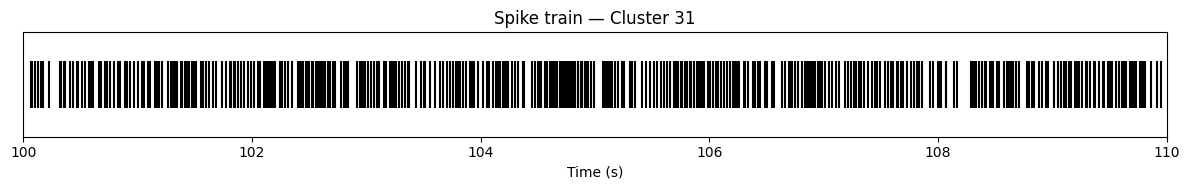

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Select one cluster for an initial visualization.
cluster_ids, spike_counts = np.unique(
    spike_clusters,
    return_counts=True
)

cluster_id = cluster_ids[np.argmax(spike_counts)]

# Extract spike times belonging to the selected cluster.
neuron_spikes = spike_times[spike_clusters == cluster_id]

print("Selected cluster:", cluster_id)
print("Number of spikes:", len(neuron_spikes))

# Visualize a 10-second segment of the spike train.
start_time = 100
end_time = 110

segment = neuron_spikes[
    (neuron_spikes >= start_time) &
    (neuron_spikes < end_time)
]

fig, ax = plt.subplots(figsize=(12, 2))

ax.eventplot(
    segment,
    orientation="horizontal",
    colors="black",
    lineoffsets=1,
    linelengths=0.7
)

ax.set_xlim(start_time, end_time)
ax.set_yticks([])
ax.set_xlabel("Time (s)")
ax.set_title(f"Spike train — Cluster {cluster_id}")
plt.tight_layout()
plt.show()


## Reproducibility checklist

- [ ] Confirm one session's subject, date, probe, and genotype.
- [ ] List available spike/cluster and trial datasets before download.
- [ ] Record session EID, download source, processing version, and quality-control rules.
- [ ] Freeze analysis definitions before genotype comparisons.
- [ ] Save only code and lightweight metadata to GitHub.


In [5]:

from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [8]:
from pathlib import Path

# Search the mounted Google Drive for the expected Excel file.
drive_root = Path("/content/drive/MyDrive")

matches = list(drive_root.rglob("behavior_list_NYU.xlsx"))

print("Files found:", len(matches))

for path in matches:
    print(path)


Files found: 1
/content/drive/MyDrive/Jan/Reanalysis/Behaviour/behavior_list_NYU.xlsx


In [11]:

# Path to the original control-group session list
file_path = "/content/drive/MyDrive/Jan/Reanalysis/Behaviour/behavior_list_NYU.xlsx"

# Read the spreadsheet without treating the first row as a header
df = pd.read_excel(file_path, header=None)

# Assign temporary column names
df.columns = [
    "subject",
    "column_2",
    "session_date",
    "column_4",
    "column_5"
]

# Inspect the corrected dataset
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head(10))


Dataset shape: (823, 5)
Column names: ['subject', 'column_2', 'session_date', 'column_4', 'column_5']


,subject,column_2,session_date,column_4,column_5
0,NYU-08,NaN,2019-10-08/,2019-10-09 07:04:00,-
1,NYU-08,NaN,2019-10-09/,2019-10-10 07:02:00,-
2,NYU-08,NaN,2019-10-10/,2019-10-12 07:03:00,-
3,NYU-08,NaN,2019-10-14/,2019-10-15 07:01:00,-
4,NYU-08,NaN,2019-10-15/,2019-10-16 07:03:00,-
5,NYU-08,NaN,2019-10-16/,2019-10-17 07:03:00,-
6,NYU-08,NaN,2019-10-17/,2019-10-23 07:05:00,-
7,NYU-08,NaN,2019-10-18/,2019-10-23 07:05:00,-
8,NYU-08,NaN,2019-10-21/,2019-10-23 07:05:00,-
9,NYU-08,NaN,2019-10-22/,2019-10-23 07:05:00,-
